# Regional forcing through CDEPS DATM

Set paths, dates, field names, and interpolation choices in **User settings**. Run Python cells in order. Blocks labeled **Terminal (CLI)** are commands to run in a shell; they are not notebook cells.

The HRRR preparation section retrieves hourly HRRR `sfc` analyses and writes a NetCDF file and ESMF source mesh on the cropped native Lambert grid. To use a prepared dataset such as ERA5, set `PREPARE_HRRR=False`, provide its NetCDF and matching ESMF mesh, and edit `FIELDS`. The notebook registers new dataset named DATM streams and reuses CDEPS's `CORE_IAF_JRA` **field processing**. It does not use JRA files, a JRA grid, or JRA stream slots.

The HRRR 2 m temperature and humidity fields are still used with the JRA routine's fixed 10 m reference height. This is a plumbing test until their reference heights and the timing of radiation and precipitation are resolved. Keep GLORYS IC/OBC coverage aligned with the run. MOM6 `diag_table` output settings are separate from DATM forcing.

In [1]:
from datetime import datetime, timedelta
from pathlib import Path
from xml.etree import ElementTree as ET
from xml.sax.saxutils import escape
import re
import shutil

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import Rectangle
from netCDF4 import Dataset

# ============================ USER SETTINGS ============================
MODE_NAME = 'HRRR'                   # Choose a unique DATM_MODE name; e.g. ERA5_REGIONAL
CASE_NAME = 'florida_storm_006hrrr_DATMextension'
INPUT_NAME = CASE_NAME               # CrocoDash input directory, if different
CESM_ROOT = Path('/glade/work/hmnguyen/crocodile2026/CESM')
CASE_ROOT = Path('/glade/u/home/hmnguyen/work/crocodile2026/croc_cases')
FORCING_ROOT = Path('/glade/work/hmnguyen/hrrr_forcing')
CACHE = Path('/glade/u/home/hmnguyen/hrrr_cache')

RUN_START = datetime(2024, 10, 1, 0)   # UTC, inclusive
RUN_END = datetime(2024, 11, 1, 0)     # UTC, exclusive
FORCING_START = datetime(2024, 10, 1, 0)
FORCING_END = datetime(2024, 11, 3, 7) # last input record; after RUN_END
GLORYS_PAD_DAYS = 2
HIST_OPTION, HIST_N = 'ndays', 1       # CESM mediator history, not MOM6 diag_table

MODEL_WEST, MODEL_EAST = 267.0, 285.0
MODEL_SOUTH, MODEL_NORTH = 25.0, 32.0
MODEL_RESOLUTION = 1 / 16

# Only used when preparing HRRR in this notebook.
PREPARE_HRRR = True
WEST, EAST, SOUTH, NORTH = 267.0, 286.0, 20.0, 33.0
HALO = 2

# For an existing dataset, set PREPARE_HRRR=False and enter BOTH paths.
# The existing file needs time,y,x fields and geographic coordinates; see below.
EXISTING_FORCING_FILE = None
EXISTING_SOURCE_MESH = None
GRID_DIMS = ('y', 'x')
LAT_NAME, LON_NAME, TIME_NAME = 'latitude', 'longitude', 'time'

# 'source' names the NetCDF variable; 'target' names the CDEPS field.
# Change source names for a prepared ERA5 file. Keep targets when reusing
# CORE_IAF_JRA processing. The Herbie selectors apply only to PREPARE_HRRR=True.
FIELDS = {
    'PREC': dict(source='PRATE', target='Faxa_prec', search=r':PRATE:surface',
                 units='kg m-2 s-1', title='surface precipitation rate', height=None,
                 tintalgo='linear', offset=0),
    'LWDN': dict(source='LWDN', target='Faxa_lwdn', search=r':DLWRF:surface',
                 units='W m-2', title='downward longwave radiation', height=None,
                 tintalgo='linear', offset=0),
    'SWDN': dict(source='SWDN', target='Faxa_swdn', search=r':DSWRF:surface',
                 units='W m-2', title='downward shortwave radiation', height=None,
                 tintalgo='linear', offset=0),
    'SHUM': dict(source='Q_2', target='Sa_shum', search=r':SPFH:2 m above ground',
                 units='kg kg-1', title='2 m specific humidity', height=2,
                 tintalgo='linear', offset=0),
    'PSLV': dict(source='SLP_', target='Sa_pslv', search=r':MSLMA:mean sea level',
                 units='Pa', title='mean sea level pressure', height=None,
                 tintalgo='linear', offset=0),
    'TBOT': dict(source='T_2', target='Sa_tbot', search=r':TMP:2 m above ground',
                 units='K', title='2 m air temperature', height=2,
                 tintalgo='linear', offset=0),
    'U': dict(source='U_10', target='Sa_u', search=r':UGRD:10 m above ground',
              units='m s-1', title='10 m geographic eastward wind', height=10,
              tintalgo='linear', offset=0),
    'V': dict(source='V_10', target='Sa_v', search=r':VGRD:10 m above ground',
              units='m s-1', title='10 m geographic northward wind', height=10,
              tintalgo='linear', offset=0),
}
# ========================== END USER SETTINGS ==========================

assert re.fullmatch(r'[A-Za-z][A-Za-z0-9_]*', MODE_NAME)
assert set(FIELDS) == {'PREC', 'LWDN', 'SWDN', 'SHUM', 'PSLV', 'TBOT', 'U', 'V'}
assert len({v['source'] for v in FIELDS.values()}) == len(FIELDS)
assert len({v['target'] for v in FIELDS.values()}) == len(FIELDS)
assert {v['target'] for v in FIELDS.values()} == {
    'Faxa_prec', 'Faxa_lwdn', 'Faxa_swdn', 'Sa_shum',
    'Sa_pslv', 'Sa_tbot', 'Sa_u', 'Sa_v'}
assert all(v['tintalgo'] in {'linear', 'nearest', 'lower', 'upper', 'coszen'}
           for v in FIELDS.values())
assert all(t.minute == t.second == t.microsecond == 0
           for t in (RUN_START, RUN_END, FORCING_START, FORCING_END))
assert FORCING_START <= RUN_START < RUN_END < FORCING_END
assert GLORYS_PAD_DAYS >= 0
N_HOURS = int((FORCING_END - FORCING_START).total_seconds() // 3600) + 1
assert FORCING_START + timedelta(hours=N_HOURS - 1) == FORCING_END
RUN_HOURS = (RUN_END - RUN_START).total_seconds() / 3600
assert RUN_HOURS.is_integer()
RUN_HOURS = int(RUN_HOURS)
STOP_OPTION = 'ndays' if RUN_HOURS % 24 == 0 else 'nhours'
STOP_N = RUN_HOURS // (24 if STOP_OPTION == 'ndays' else 1)
GLORYS_DATE_RANGE = [f'{RUN_START:%Y-%m-%d %H:%M:%S}',
                     f'{RUN_END + timedelta(days=GLORYS_PAD_DAYS):%Y-%m-%d %H:%M:%S}']

CASE = CASE_ROOT / CASE_NAME
OUT = FORCING_ROOT / CASE_NAME
OUT.mkdir(parents=True, exist_ok=True)
if PREPARE_HRRR:
    assert GRID_DIMS == ('y', 'x') and (LAT_NAME, LON_NAME, TIME_NAME) == (
        'latitude', 'longitude', 'time')
    CACHE.mkdir(parents=True, exist_ok=True)
    FORCING_FILE = OUT / f'{MODE_NAME}_DATM_{FORCING_START:%Y%m%d%H}_{FORCING_END:%Y%m%d%H}.nc'
    SOURCE_MESH = OUT / f'{MODE_NAME}_ESMFmesh.nc'
else:
    assert EXISTING_FORCING_FILE is not None and EXISTING_SOURCE_MESH is not None
    FORCING_FILE = Path(EXISTING_FORCING_FILE).expanduser().resolve()
    SOURCE_MESH = Path(EXISTING_SOURCE_MESH).expanduser().resolve()
ATM_MESH = OUT / 'Regional_ATM_ESMFmesh.nc'
CONFIG_DIR = CESM_ROOT / 'components/cdeps/datm/cime_config'
SOURCE_BY_TARGET = {spec['target']: spec['source'] for spec in FIELDS.values()}
U_NAME, V_NAME = SOURCE_BY_TARGET['Sa_u'], SOURCE_BY_TARGET['Sa_v']
T_NAME, Q_NAME = SOURCE_BY_TARGET['Sa_tbot'], SOURCE_BY_TARGET['Sa_shum']
P_NAME, R_NAME = SOURCE_BY_TARGET['Sa_pslv'], SOURCE_BY_TARGET['Faxa_prec']
FIELD = {spec['source']: spec['search'] for spec in FIELDS.values()}
UNITS = {spec['source']: spec['units'] for spec in FIELDS.values()}

print('Case:', CASE)
print('DATM_MODE:', MODE_NAME, '| underlying datamode: CORE_IAF_JRA')
print('Forcing:', FORCING_FILE, '| source mesh:', SOURCE_MESH)
print('ATM model mesh:', ATM_MESH)
print('Run:', RUN_START, 'through', RUN_END, 'UTC |', STOP_OPTION, STOP_N)
print('Input records:', FORCING_START, 'through', FORCING_END, 'UTC')
print('GLORYS date_range:', GLORYS_DATE_RANGE)
print('Mediator history:', HIST_OPTION, HIST_N)

Case: /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_006hrrr_DATMextension
DATM_MODE: HRRR | underlying datamode: CORE_IAF_JRA
Forcing: /glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/HRRR_DATM_2024100100_2024110307.nc | source mesh: /glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/HRRR_ESMFmesh.nc
ATM model mesh: /glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/Regional_ATM_ESMFmesh.nc
Run: 2024-10-01 00:00:00 through 2024-11-01 00:00:00 UTC | ndays 31
Input records: 2024-10-01 00:00:00 through 2024-11-03 07:00:00 UTC
GLORYS date_range: ['2024-10-01 00:00:00', '2024-11-03 00:00:00']
Mediator history: ndays 1


## 1. Prepare the forcing and source mesh

With `PREPARE_HRRR=True`, the next cells download one HRRR surface analysis per UTC hour. Herbie selects only the eight GRIB messages in `FIELDS`. The output retains HRRR's Lambert `(y, x)` grid. With `PREPARE_HRRR=False`, skip to **Validate the prepared forcing**; supply a file and mesh made for the other dataset.

For another data source, prepare fields with the stated physical units and a matching ESMF source mesh first. Changing a name in `FIELDS` does not convert units, reference heights, forecast accumulations, or wind orientation.

In [2]:
if PREPARE_HRRR:
    from herbie import Herbie
    from IPython.display import display
    h0 = Herbie(FORCING_START, model='hrrr', product='sfc', fxx=0, save_dir=CACHE)
    for target, search in FIELD.items():
        inventory = h0.inventory(search)
        print(f'\n{target}: {len(inventory)} message(s)')
        display(inventory)
        assert len(inventory) == 1, (target, search, 'Inspect inventory before continuing')

/glade/work/hmnguyen/conda-envs/testRun/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local

PRATE: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
82,83,48147511,48147698.0,48147511-48147698,2024-10-01,2024-10-01,PRATE,surface,anl,:PRATE:surface:anl



LWDN: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
123,124,73115428,74983256.0,73115428-74983256,2024-10-01,2024-10-01,DLWRF,surface,anl,:DLWRF:surface:anl



SWDN: 1 message(s)


... (7 outputs left out)


U_10: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
76,77,40317744,42699358.0,40317744-42699358,2024-10-01,2024-10-01,UGRD,10 m above ground,anl,:UGRD:10 m above ground:anl



V_10: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
77,78,42699359,44842830.0,42699359-44842830,2024-10-01,2024-10-01,VGRD,10 m above ground,anl,:VGRD:10 m above ground:anl


### Read GRIB and check wind orientation

Herbie/cfgrib reads the selected fields. The GRIB `uvRelativeToGrid` flag tells whether the wind components follow Lambert grid axes (`1`) or geographic east/north (`0`). Python ecCodes is used if cfgrib does not expose the flag.

In [3]:
if PREPARE_HRRR:
    def read_field(h, search):
        ds = h.xarray(search, remove_grib=False)
        if isinstance(ds, list):
            assert len(ds) == 1, (search, len(ds))
            ds = ds[0]
        names = list(ds.data_vars)
        assert len(names) == 1, (search, names)
        da = ds[names[0]].load()
        assert da.dims == ('y', 'x'), (search, da.dims)
        return da


    def wind_grid_flag(da, h, search):
        flag = da.attrs.get('GRIB_uvRelativeToGrid')
        if flag is None:
            try:
                from eccodes import codes_grib_new_from_file, codes_get, codes_release
            except ImportError as exc:
                raise RuntimeError('Install Python eccodes or expose GRIB_uvRelativeToGrid; do not guess wind orientation') from exc
            grib_path = Path(h.get_localFilePath(search))
            assert grib_path.is_file(), grib_path
            with grib_path.open('rb') as fh:
                message = codes_grib_new_from_file(fh)
                if message is None:
                    raise RuntimeError(f'No GRIB message: {grib_path}')
                try:
                    flag = codes_get(message, 'uvRelativeToGrid')
                finally:
                    codes_release(message)
        flag = int(flag)
        assert flag in (0, 1), flag  # 0 geographic, 1 Lambert-grid relative
        return flag


    u0 = read_field(h0, FIELD[U_NAME])
    v0 = read_field(h0, FIELD[V_NAME])
    u_flag = wind_grid_flag(u0, h0, FIELD[U_NAME])
    v_flag = wind_grid_flag(v0, h0, FIELD[V_NAME])
    assert u_flag == v_flag, (u_flag, v_flag)
    print('Wind orientation:', 'grid-relative; rotate both components' if u_flag else 'geographic east/north')
    print('HRRR grid:', u0.shape)

Wind orientation: grid-relative; rotate both components
HRRR grid: (1059, 1799)


### Crop on the native grid

Find HRRR cell centers inside the geographic box, then take the smallest rectangular `(y, x)` slice with `HALO` additional cells. Its edge is curved in longitude/latitude because the original grid is Lambert conformal. Cropping is not regridding.

In [4]:
if PREPARE_HRRR:
    lat_full = np.asarray(u0.latitude.values, dtype=np.float64)
    lon_full = np.asarray(u0.longitude.values, dtype=np.float64) % 360.0
    assert lat_full.shape == lon_full.shape == u0.shape
    np.testing.assert_allclose(v0.latitude.values, lat_full)
    np.testing.assert_allclose(v0.longitude.values % 360.0, lon_full)

    inside = ((lon_full >= WEST) & (lon_full <= EAST) &
              (lat_full >= SOUTH) & (lat_full <= NORTH))
    jj, ii = np.where(inside)
    assert len(jj), 'No HRRR cells in requested region'
    ys = slice(max(0, int(jj.min()) - HALO), min(u0.shape[0], int(jj.max()) + HALO + 1))
    xs = slice(max(0, int(ii.min()) - HALO), min(u0.shape[1], int(ii.max()) + HALO + 1))
    lat, lon = lat_full[ys, xs], lon_full[ys, xs]
    ny, nx = lat.shape
    assert ny >= 2 and nx >= 2 and np.isfinite(lat).all() and np.isfinite(lon).all()
    print('Native HRRR subset (y, x):', (ny, nx), 'slices:', ys, xs)

Native HRRR subset (y, x): (421, 699) slices: slice(0, 421, None) slice(1038, 1737, None)


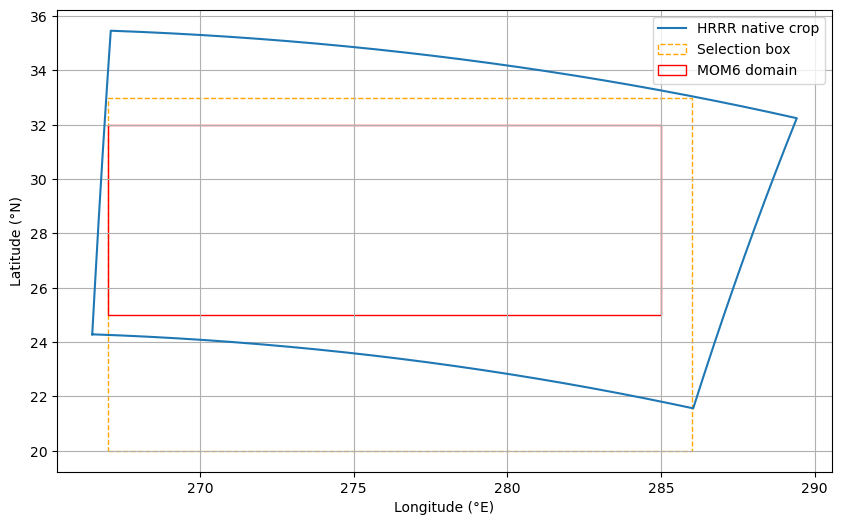

In [5]:
if PREPARE_HRRR:
    boundary_lon = np.r_[lon[0, :], lon[1:, -1], lon[-1, -2::-1], lon[-2:0:-1, 0]]
    boundary_lat = np.r_[lat[0, :], lat[1:, -1], lat[-1, -2::-1], lat[-2:0:-1, 0]]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(np.r_[boundary_lon, boundary_lon[0]], np.r_[boundary_lat, boundary_lat[0]], label='HRRR native crop')
    ax.add_patch(Rectangle((WEST, SOUTH), EAST-WEST, NORTH-SOUTH, fill=False,
                           edgecolor='orange', linestyle='--', label='Selection box'))
    ax.add_patch(Rectangle((MODEL_WEST, MODEL_SOUTH), MODEL_EAST-MODEL_WEST,
                           MODEL_NORTH-MODEL_SOUTH, fill=False, edgecolor='red', label='MOM6 domain'))
    ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)')
    ax.legend(); ax.grid(); plt.show()

    test_lon, test_lat = np.meshgrid(np.linspace(MODEL_WEST, MODEL_EAST, 181),
                                     np.linspace(MODEL_SOUTH, MODEL_NORTH, 71))
    outline = MplPath(np.column_stack((boundary_lon, boundary_lat)), closed=True)
    assert outline.contains_points(np.column_stack((test_lon.ravel(), test_lat.ravel()))).all(), \
        'The proposed MOM6 rectangle extends outside the native HRRR crop'

### Rotate winds and assemble hourly fields

For grid-relative winds, geodesic bearings between adjacent cell centers define the geographic directions of HRRR's `x` and `y` axes. The code projects `(u, v)` onto east and north before writing. It checks the orientation flag, coordinates, finite values, and grid shape for every hour.

In [6]:
if PREPARE_HRRR:
    from pyproj import Geod
    geod = Geod(ellps='WGS84')
    az_x = np.empty((ny, nx), dtype=np.float64)
    az_y = np.empty((ny, nx), dtype=np.float64)
    az_x[:, :-1], _, _ = geod.inv(lon[:, :-1], lat[:, :-1], lon[:, 1:], lat[:, 1:])
    az_x[:, -1] = az_x[:, -2]
    az_y[:-1, :], _, _ = geod.inv(lon[:-1, :], lat[:-1, :], lon[1:, :], lat[1:, :])
    az_y[-1, :] = az_y[-2, :]
    sx, cx = np.sin(np.deg2rad(az_x)), np.cos(np.deg2rad(az_x))
    sy, cy = np.sin(np.deg2rad(az_y)), np.cos(np.deg2rad(az_y))
    assert np.nanmin(sx) > 0 and np.nanmin(cy) > 0, 'Unexpected axis direction; inspect geometry'
    assert np.nanmax(np.abs(sx * sy + cx * cy)) < 0.05, 'HRRR grid axes are unexpectedly nonorthogonal'

    def earth_winds(u, v):
        if u_flag == 0:
            return u, v
        return u * sx + v * sy, u * cx + v * cy

    print('Rotation ready; GRIB flag:', u_flag)

Rotation ready; GRIB flag: 1


In [7]:
if PREPARE_HRRR:
    hourly = {key: [] for key in FIELD}
    metadata = {}

    for hour in range(N_HOURS):
        valid = FORCING_START + timedelta(hours=hour)
        h = h0 if hour == 0 else Herbie(valid, model='hrrr', product='sfc', fxx=0, save_dir=CACHE)
        fields = {}
        for key, search in FIELD.items():
            da = ({U_NAME: u0, V_NAME: v0}[key] if hour == 0 and key in (U_NAME, V_NAME)
                  else read_field(h, search))
            np.testing.assert_allclose(da.latitude.values[ys, xs], lat, atol=1e-5)
            np.testing.assert_allclose(da.longitude.values[ys, xs] % 360.0, lon, atol=1e-5)
            values = np.asarray(da.values[ys, xs], dtype=np.float64)
            if not np.isfinite(values).all():
                raise ValueError(f'{key} contains missing HRRR values at {valid}')
            fields[key] = values
            metadata.setdefault(key, {name: da.attrs.get(name) for name in ('units', 'GRIB_units', 'GRIB_stepType')})
            if key in (U_NAME, V_NAME):
                assert wind_grid_flag(da, h, search) == u_flag, (key, valid)

        fields[U_NAME], fields[V_NAME] = earth_winds(fields[U_NAME], fields[V_NAME])
        for key, values in fields.items():
            hourly[key].append(values.astype('float32'))
        print(f'{valid:%Y-%m-%d %H:%M} UTC: all requested fields')

    data = {key: np.stack(hourly[key]) for key in FIELD}
    assert all(a.shape == (N_HOURS, ny, nx) for a in data.values())
    for key, a in data.items():
        print(key, metadata[key], 'range:', (float(a.min()), float(a.max())))

2024-10-01 00:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 01:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 01:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 02:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 02:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 03:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 03:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 04:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 04:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 05:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 05:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 06:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 06:00 UTC: all requested fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-01 07:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-01 07:00 UTC: all requested fields
✅ Found ┊ model=hrr

### Check units and ranges

The unit checks protect the HRRR preparation path against selecting a different GRIB field. Inspect the printed `GRIB_stepType` for SWDN, LWDN, and PRATE: a forecast accumulation needs appropriate conversion and time labeling before it becomes an instantaneous or interval-mean flux.

In [8]:
if PREPARE_HRRR:
    def unit_key(value):
        return (str(value).lower().replace(' ', '').replace('**', '').replace('^', '')
                .replace('−', '-').replace('·', ''))

    accepted = {
        U_NAME: {'ms-1', 'm/s'}, V_NAME: {'ms-1', 'm/s'},
        T_NAME: {'k'}, Q_NAME: {'kgkg-1', 'kg/kg'},
        P_NAME: {'pa'}, SOURCE_BY_TARGET['Faxa_swdn']: {'wm-2', 'w/m2'},
        SOURCE_BY_TARGET['Faxa_lwdn']: {'wm-2', 'w/m2'},
        R_NAME: {'kgm-2s-1', 'kg/m2/s'},
    }
    for key, attrs in metadata.items():
        supplied = [attrs.get('GRIB_units'), attrs.get('units')]
        assert any(unit_key(u) in accepted[key] for u in supplied if u is not None), (key, supplied)
    assert 240 < float(data[T_NAME].min()) < float(data[T_NAME].max()) < 330
    assert 0 <= float(data[Q_NAME].min()) < float(data[Q_NAME].max()) < 0.05
    assert 85000 < float(data[P_NAME].min()) < float(data[P_NAME].max()) < 110000
    assert float(data[R_NAME].min()) >= 0
    print('Units and basic ranges pass. Review stepType above, especially SWDN/LWDN/PRATE.')

Units and basic ranges pass. Review stepType above, especially SWDN/LWDN/PRATE.


### Write the HRRR ESMF mesh and NetCDF

For each selected HRRR center, the mesh stores its geographic center and four surrounding corners. Corners are estimated from nearby centers, with edge extrapolation. `elementConn` links each quadrilateral to its nodes using **one-based indexing**; flattening follows NetCDF `(y, x)` order. These are geographical coordinates describing Lambert cells, not cells on a new lat/lon grid.

CDEPS reads the source mesh, maps its cells onto the regional ATM model mesh with `mapalgo=bilinear`, and then supplies fields to the mediator. No HRRR-to-JRA offline remapping occurs. Check the crop boundary and model-mesh coverage below; corner extrapolation is an approximation near the edges.

In [9]:
if PREPARE_HRRR:
    def centers_to_corners(a):
        ny0, nx0 = a.shape
        ext = np.empty((ny0 + 2, nx0 + 2), dtype='float64')
        ext[1:-1, 1:-1] = a
        ext[0, 1:-1] = 2*a[0, :] - a[1, :]
        ext[-1, 1:-1] = 2*a[-1, :] - a[-2, :]
        ext[:, 0] = 2*ext[:, 1] - ext[:, 2]
        ext[:, -1] = 2*ext[:, -2] - ext[:, -3]
        return 0.25 * (ext[:-1, :-1] + ext[1:, :-1] + ext[:-1, 1:] + ext[1:, 1:])

    unwrapped = np.rad2deg(np.unwrap(np.unwrap(np.deg2rad(lon), axis=1), axis=0))
    assert np.median(np.diff(unwrapped, axis=1)) > 0
    assert np.median(np.diff(lat, axis=0)) > 0
    corner_lon, corner_lat = centers_to_corners(unwrapped), centers_to_corners(lat)
    nodes = np.arange(1, (ny + 1)*(nx + 1) + 1, dtype='int32').reshape(ny + 1, nx + 1)
    conn = np.stack((nodes[:-1, :-1], nodes[:-1, 1:], nodes[1:, 1:], nodes[1:, :-1]),
                    axis=-1).reshape(ny*nx, 4)

    mesh = xr.Dataset(
        data_vars={
            'nodeCoords': (('nodeCount', 'coordDim'),
                           np.column_stack(((corner_lon % 360).ravel(), corner_lat.ravel())), {'units': 'degrees'}),
            'elementConn': (('elementCount', 'maxNodePElement'), conn, {'start_index': 1}),
            'numElementConn': (('elementCount',), np.full(ny*nx, 4, dtype='int32')),
            'centerCoords': (('elementCount', 'coordDim'),
                             np.column_stack((lon.ravel(), lat.ravel())), {'units': 'degrees'}),
            'elementMask': (('elementCount',), np.ones(ny*nx, dtype='int32')),
            'origGridDims': (('origGridRank',), np.array([nx, ny], dtype='int32')),
        }, attrs={'gridType': 'unstructured', 'version': '0.9',
                  'conventions': 'ESMFMESH', 'title': f'Native {MODE_NAME} Lambert crop'})
    mesh.to_netcdf(SOURCE_MESH, format='NETCDF4_CLASSIC',
                   encoding={name: {'_FillValue': None} for name in mesh.variables})
    print(SOURCE_MESH, 'elements:', ny*nx)

/glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/HRRR_ESMFmesh.nc elements: 294279


In [10]:
if PREPARE_HRRR:
    details = {spec['source']: (spec['title'], spec['height'])
               for spec in FIELDS.values()}
    variables = {}
    for key, values in data.items():
        description, height = details[key]
        attrs = {'units': UNITS[key], 'long_name': description,
                 'HRRR_stepType': str(metadata[key].get('GRIB_stepType'))}
        if height is not None:
            attrs['reference_height_m'] = height
        variables[key] = (('time', 'y', 'x'), values, attrs)

    forcing = xr.Dataset(
        data_vars=variables,
        coords={
            'time': (('time',), np.arange(N_HOURS, dtype='float64'),
                     {'units': f'hours since {FORCING_START:%Y-%m-%d %H:%M:%S}', 'calendar': 'gregorian'}),
            'latitude': (('y', 'x'), lat, {'units': 'degrees_north'}),
            'longitude': (('y', 'x'), lon, {'units': 'degrees_east'}),
        }, attrs={'source': f'{MODE_NAME}: HRRR sfc f00 analysis on native Lambert grid',
                  'wind_orientation': 'geographic east/north',
                  'purpose': 'DATM interface test; thermodynamic height and flux timing need review'})
    forcing.to_netcdf(FORCING_FILE, format='NETCDF4_CLASSIC',
                      encoding={k: {'zlib': True, 'complevel': 2,
                                    '_FillValue': np.float32(1e20)} for k in FIELD})
    print(FORCING_FILE)

/glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/HRRR_DATM_2024100100_2024110307.nc


## 2. Validate the prepared forcing

This cell also runs when using a file prepared elsewhere. Required fields must have `(time, *GRID_DIMS)` dimensions, decodable hourly Gregorian times bracketing the run, and matching geographic centers in the ESMF mesh. For a regular ERA5 grid, set `GRID_DIMS`, `LAT_NAME`, and `LON_NAME`; one-dimensional latitude and longitude coordinates are broadcast into a 2D array for the mesh-order check. Supply an ESMF mesh made for that dataset's actual grid.

In [11]:
assert FORCING_FILE.is_file() and SOURCE_MESH.is_file(), (FORCING_FILE, SOURCE_MESH)
with xr.open_dataset(FORCING_FILE) as check, \
     xr.open_dataset(SOURCE_MESH, decode_times=False) as checkmesh:
    required = {spec['source'] for spec in FIELDS.values()}
    assert required <= set(check.data_vars), ('Missing input variables', required - set(check.data_vars))
    assert LAT_NAME in check and LON_NAME in check and TIME_NAME in check
    lat_da, lon_da = xr.broadcast(check[LAT_NAME], check[LON_NAME])
    lat = np.asarray(lat_da.transpose(*GRID_DIMS).values, dtype='float64')
    lon = np.asarray(lon_da.transpose(*GRID_DIMS).values, dtype='float64') % 360.0
    ny, nx = lat.shape
    assert np.isfinite(lat).all() and np.isfinite(lon).all()
    times = np.asarray(check[TIME_NAME].values)
    assert np.issubdtype(times.dtype, np.datetime64), (
        'Use a decodable Gregorian time axis for this notebook', times.dtype)
    assert len(times) >= 2 and np.all(np.diff(times) > np.timedelta64(0, 's'))
    assert times[0] <= np.datetime64(FORCING_START)
    assert times[-1] >= np.datetime64(FORCING_END)
    for spec in FIELDS.values():
        da = check[spec['source']]
        assert da.dims == (TIME_NAME, *GRID_DIMS), (spec['source'], da.dims)
        assert da.shape[1:] == (ny, nx)
        for index in (0, len(times)-1):
            values = np.asarray(da.isel({TIME_NAME: index}).values)
            assert np.isfinite(values).all(), (spec['source'], index, 'nonfinite values')
    assert checkmesh.sizes['elementCount'] == ny * nx
    centers = np.asarray(checkmesh.centerCoords.values)
    np.testing.assert_allclose(centers[:, 0] % 360.0, lon.ravel(), atol=1e-5)
    np.testing.assert_allclose(centers[:, 1], lat.ravel(), atol=1e-5)
    assert np.all(np.asarray(checkmesh.elementMask.values) == 1)
    if 'origGridDims' in checkmesh:
        np.testing.assert_array_equal(checkmesh.origGridDims.values, [nx, ny])

boundary_lon = np.r_[lon[0, :], lon[1:, -1], lon[-1, -2::-1], lon[-2:0:-1, 0]]
boundary_lat = np.r_[lat[0, :], lat[1:, -1], lat[-1, -2::-1], lat[-2:0:-1, 0]]
outline = MplPath(np.column_stack((boundary_lon, boundary_lat)), closed=True)
test_lon, test_lat = np.meshgrid(np.linspace(MODEL_WEST, MODEL_EAST, 181),
                                 np.linspace(MODEL_SOUTH, MODEL_NORTH, 71))
assert outline.contains_points(np.column_stack((test_lon.ravel(), test_lat.ravel()))).all(), \
    'Model rectangle extends beyond source grid; extend the source grid/mesh'
print(f'{len(FIELDS)} fields, source mesh ordering, and time coverage verified:',
      str(times[0]), 'to', str(times[-1]))

8 fields, source mesh ordering, and time coverage verified: 2024-10-01T00:00:00.000000000 to 2024-11-03T07:00:00.000000000


## 3. Register a dataset named DATM mode in CDEPS

This changes three files in the **CESM source checkout**. It adds `MODE_NAME` as a valid CIME `DATM_MODE`, defines its stream list, maps it to the existing `CORE_IAF_JRA` processing routine, and registers each dataset named stream with its own file, source mesh, and interpolation. The source files are shared by cases using this checkout: use a distinct mode name when registering a different dataset or forcing period.

The cell is repeatable for its own stream-definition block. It refuses to replace an unrelated pre-existing mode. Review its printed changes and save the three XML files in version control. Creating a fresh case *after* this cell makes its `env_run.xml` recognize the new `DATM_MODE`.

In [12]:
component_xml = CONFIG_DIR / 'config_component.xml'
namelist_xml = CONFIG_DIR / 'namelist_definition_datm.xml'
streams_xml = CONFIG_DIR / 'stream_definition_datm.xml'
for path in (component_xml, namelist_xml, streams_xml):
    assert path.is_file(), ('Wrong CESM_ROOT?', path)

mode_names = [f'{MODE_NAME}.{slot}' for slot in FIELDS]
component_text = component_xml.read_text()
namelist_text = namelist_xml.read_text()
streams_text = streams_xml.read_text()

def entry_block(document, entry_id):
    match = re.search(r'<entry id="' + re.escape(entry_id) +
                      r'"[^>]*>.*?</entry>', document, re.S)
    if match is None:
        raise ValueError(f'Could not find XML entry {entry_id}')
    return match

# 1: Permit DATM_MODE=<MODE_NAME> in cases created from this checkout.
match = entry_block(component_text, 'DATM_MODE')
block = match.group()
valid = re.search(r'<valid_values>([^<]*)</valid_values>', block)
assert valid, 'DATM_MODE valid_values changed; inspect config_component.xml'
allowed = [v.strip() for v in valid.group(1).split(',')]
already_registered = MODE_NAME in allowed
if not already_registered:
    updated = block[:valid.start(1)] + valid.group(1) + ',' + MODE_NAME + block[valid.end(1):]
    component_text = component_text[:match.start()] + updated + component_text[match.end():]

# 2: Assign new stream names, but reuse the field-processing data mode.
match = entry_block(namelist_text, 'streamslist')
block = match.group()
if f'datm_mode="{MODE_NAME}"' not in block:
    new_value = f'\n      <value datm_mode="{MODE_NAME}">\n        {",".join(mode_names)}\n      </value>'
    block = block.replace('<values>', '<values>' + new_value, 1)
    namelist_text = namelist_text[:match.start()] + block + namelist_text[match.end():]
else:
    assert all(name in block for name in mode_names), 'Existing stream list conflicts with settings'

match = entry_block(namelist_text, 'datamode')
block = match.group()
if f'datm_mode="{MODE_NAME}"' not in block:
    new_value = f'\n      <value datm_mode="{MODE_NAME}">CORE_IAF_JRA</value>'
    block = block.replace('<values>', '<values>' + new_value, 1)
    namelist_text = namelist_text[:match.start()] + block + namelist_text[match.end():]
else:
    assert re.search(r'<value datm_mode="' + re.escape(MODE_NAME) +
                     r'">\s*CORE_IAF_JRA\s*</value>', block), 'Existing datamode differs'

# 3: One independent source stream per field. All may read the same NetCDF.
start_marker = f'  <!-- BEGIN notebook DATM mode {MODE_NAME} -->'
end_marker = f'  <!-- END notebook DATM mode {MODE_NAME} -->'
if already_registered and start_marker not in streams_text:
    raise ValueError(f'{MODE_NAME} already exists without this notebook block; choose a new MODE_NAME')
parts = [start_marker]
for slot, spec in FIELDS.items():
    file_name = str(FORCING_FILE.expanduser().resolve())
    mesh_name = str(SOURCE_MESH.expanduser().resolve())
    assert Path(file_name).is_file() and Path(mesh_name).is_file(), (slot, file_name, mesh_name)
    assert '\n' not in file_name + mesh_name + spec['source']
    parts.append(f'''  <stream_entry name="{escape(MODE_NAME)}.{escape(slot)}">
    <stream_meshfile><meshfile>{escape(mesh_name)}</meshfile></stream_meshfile>
    <stream_datafiles><file>{escape(file_name)}</file></stream_datafiles>
    <stream_datavars><var>{escape(spec['source'])} {escape(spec['target'])}</var></stream_datavars>
    <stream_lev_dimname>null</stream_lev_dimname>
    <stream_mapalgo><mapalgo>bilinear</mapalgo></stream_mapalgo>
    <stream_vectors>null</stream_vectors>
    <stream_year_align>{FORCING_START.year}</stream_year_align>
    <stream_year_first>{FORCING_START.year}</stream_year_first>
    <stream_year_last>{FORCING_END.year}</stream_year_last>
    <stream_offset>{int(spec['offset'])}</stream_offset>
    <stream_tintalgo><tintalgo>{spec['tintalgo']}</tintalgo></stream_tintalgo>
    <stream_taxmode><taxmode>limit</taxmode></stream_taxmode>
    <stream_dtlimit><dtlimit>1.5</dtlimit></stream_dtlimit>
    <stream_readmode>single</stream_readmode>
  </stream_entry>''')
parts.append(end_marker)
new_block = '\n'.join(parts)
if start_marker in streams_text:
    assert streams_text.count(start_marker) == streams_text.count(end_marker) == 1
    left = streams_text.index(start_marker)
    right = streams_text.index(end_marker) + len(end_marker)
    streams_text = streams_text[:left] + new_block + streams_text[right:]
else:
    assert streams_text.count('</stream_data>') == 1
    streams_text = streams_text.replace('</stream_data>', new_block + '\n\n</stream_data>')

# Parse all files before writing any of them.
for path, value in ((component_xml, component_text),
                    (namelist_xml, namelist_text), (streams_xml, streams_text)):
    ET.fromstring(value)
    if path.read_text() != value:
        path.write_text(value)
        print('Updated:', path)
    else:
        print('Already current:', path)
print('Registered', MODE_NAME, 'with', len(FIELDS), 'dataset named streams.')

Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/config_component.xml
Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/namelist_definition_datm.xml
Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/stream_definition_datm.xml
Registered HRRR with 8 dataset named streams.


**Terminal (CLI): inspect the source edits**

```bash
cd <CESM_checkout>/components/cdeps
git diff -- datm/cime_config/config_component.xml datm/cime_config/namelist_definition_datm.xml datm/cime_config/stream_definition_datm.xml
```

These source XML changes define the mode for new cases. They do not yet modify or build a case.

## CHECKPOINT A — generate a fresh CrocoDash case

Create a new case in the checkout configured above. Use `CASE_NAME`, `INPUT_NAME`, `MODEL_*`, and `MODEL_RESOLUTION` from User settings with your existing CrocoDash case-generation cells. Generate GLORYS IC/OBC through `GLORYS_DATE_RANGE`:

```python
from CrocoDash.grid import Grid

grid = Grid(
    resolution=MODEL_RESOLUTION,
    xstart=MODEL_WEST, lenx=MODEL_EAST-MODEL_WEST,
    ystart=MODEL_SOUTH, leny=MODEL_NORTH-MODEL_SOUTH,
    name=INPUT_NAME,
)
# Pass grid and CASE_NAME to your usual CrocoDash case creation calls.
case.configure_forcings(
    date_range=GLORYS_DATE_RANGE,
    boundaries=['south', 'north', 'west', 'east'],
    product_name='GLORYS',
    function_name='get_glorys_data_from_rda',
)
case.process_forcings()
```

If CrocoDash runs in another notebook, copy the **printed** settings there; kernels do not share variables. Create the case and return here when `env_run.xml` exists. Complete any usual CrocoDash setup steps required for MOM6 IC/OBC. Do not copy an old case's `user_nl_datm_streams` file.

In [13]:
assert CASE.is_dir(), f'Create the new CrocoDash case first: {CASE}'
assert (CASE / 'env_run.xml').is_file()
entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
print({key: entries.get(key) for key in
       ('DATM_MODE', 'CALENDAR', 'RUN_STARTDATE', 'OCN_DOMAIN_MESH', 'ATM_DOMAIN_MESH')})
assert entries.get('CALENDAR', '').lower() in ('gregorian', 'standard')
ocean_mesh = Path(entries['OCN_DOMAIN_MESH'])
assert ocean_mesh.is_file(), ocean_mesh
assert INPUT_NAME in str(ocean_mesh), ('Check INPUT_NAME and ocean mesh', ocean_mesh)

datm_entry = next(e for e in ET.parse(CASE / 'env_run.xml').iter('entry')
                  if e.get('id') == 'DATM_MODE')
case_allowed = datm_entry.find('valid_values')
if case_allowed is not None:
    assert MODE_NAME in (case_allowed.text or '').split(','), (
        'Case does not recognize the new mode. Create it after the CDEPS XML edits.', MODE_NAME)

{'DATM_MODE': 'CORE_IAF_JRA_1p5_2023', 'CALENDAR': 'GREGORIAN', 'RUN_STARTDATE': '2024-10-01', 'OCN_DOMAIN_MESH': '/glade/work/hmnguyen/crocodile2026/croc_input/florida_storm_006hrrr_DATMextension/ocn/ESMF_mesh_florida_storm_006hrrr_DATMextension_e7746f.nc', 'ATM_DOMAIN_MESH': '/glade/campaign/cesm/cesmdata/inputdata/share/meshes/TL319_151007_ESMFmesh.nc'}


### Create the regional ATM model mesh

`SOURCE_MESH` describes the forcing grid. `ATM_MESH` describes the **regional model grid** that DATM exports to. Copy the case's ocean mesh and activate all its ATM elements, including coastal land cells. Keep the original ocean wet/dry mask. This avoids gaps when DATM interpolates atmospheric fields near the coast.

In [14]:
assert ocean_mesh.resolve() != ATM_MESH.resolve()
shutil.copy2(ocean_mesh, ATM_MESH)
with Dataset(ATM_MESH, 'r+') as nc:
    mask = nc.variables['elementMask']
    mask[:] = np.ones(mask.shape, dtype=mask.dtype)
with Dataset(ATM_MESH) as atm, Dataset(ocean_mesh) as ocn:
    atm_mask = np.asarray(atm.variables['elementMask'][:])
    ocn_mask = np.asarray(ocn.variables['elementMask'][:])
    assert np.all(atm_mask == 1)
    assert np.any(ocn_mask == 1)
    print('Ocean mask:', dict(zip(*[v.tolist() for v in np.unique(ocn_mask, return_counts=True)])))
    print('ATM mesh:', ATM_MESH, 'elements:', len(atm_mask), 'all active')
    centers = np.asarray(ocn.variables['centerCoords'][:])
    wet = centers[ocn_mask == 1]
    wet[:, 0] %= 360
    outside = ~outline.contains_points(wet, radius=1e-9)
    assert outside.sum() == 0, f'{outside.sum()} wet ocean cells outside the source mesh footprint'

Ocean mask: {0: 10394, 1: 21862}
ATM mesh: /glade/work/hmnguyen/hrrr_forcing/florida_storm_006hrrr_DATMextension/Regional_ATM_ESMFmesh.nc elements: 32256 all active


### Remove stale CrocoDash JRA stream-year overrides

CrocoDash `configure_forcings` can write a JRA `StreamYears` block into `user_nl_datm_streams`. This new mode has its **own** stream names and years in CDEPS, so remove that generated block. This cell will stop if it finds any other active override; inspect it before proceeding.

In [ ]:
override_file = CASE / 'user_nl_datm_streams'
existing = override_file.read_text() if override_file.exists() else ''
auto_block = re.compile(
    r'(?ms)^! >>> CrocoDash configure_forcings: StreamYears[^\n]*\n'
    r'.*?^! <<< CrocoDash configure_forcings: StreamYears[^\n]*(?:\n|$)'
)
cleaned, removed = auto_block.subn('', existing)
assert removed <= 1 and 'CrocoDash configure_forcings: StreamYears' not in cleaned
active_lines = [line for line in cleaned.splitlines()
                if line.strip() and not line.lstrip().startswith('!')]
assert not active_lines, ('Inspect unrelated DATM stream overrides before proceeding', active_lines)
if cleaned != existing:
    override_file.write_text(cleaned)
print('Removed stale JRA StreamYears block:', removed)

**Terminal (CLI): select the mode and preview the case**

Replace placeholders with values printed by User settings. Set `ATM_DOMAIN_MESH` to the **regional** all-active mesh; each forcing stream uses `SOURCE_MESH` from the CDEPS XML. Keep `OCN_DOMAIN_MESH` unchanged.

```bash
cd <new_case_directory>
./xmlchange DATM_MODE=<MODE_NAME>,ATM_DOMAIN_MESH=<regional_ATM_mesh_path>
./xmlchange RUN_STARTDATE=<YYYY-MM-DD>,STOP_OPTION=<ndays_or_nhours>,STOP_N=<integer>,HIST_OPTION=<history_option>,HIST_N=<integer>
./preview_namelists
```

If `DATM_MODE` is rejected as invalid, the case was generated before this checkout's `config_component.xml` change, or was generated from a different CDEPS checkout. Create a fresh case using the edited checkout.

## 4. Check the generated CDEPS configuration

After `./preview_namelists`, the case must have `datamode="CORE_IAF_JRA"`, the regional ATM model mesh, and exactly the dataset named forcing streams with your file, source mesh, and variable mappings. A JRA datafile or active JRA stream indicates that the new mode was not selected.

In [16]:
run_entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
assert run_entries.get('DATM_MODE') == MODE_NAME, run_entries.get('DATM_MODE')
assert run_entries.get('ATM_DOMAIN_MESH') == str(ATM_MESH)
assert run_entries.get('OCN_DOMAIN_MESH') == str(ocean_mesh)
assert run_entries.get('RUN_STARTDATE') == f'{RUN_START:%Y-%m-%d}'
assert run_entries.get('STOP_OPTION') == STOP_OPTION
assert int(run_entries.get('STOP_N', '-1')) == STOP_N
assert run_entries.get('HIST_OPTION') == HIST_OPTION
assert int(run_entries.get('HIST_N', '-1')) == HIST_N

datm_in = (CASE / 'CaseDocs/datm_in').read_text()
assert re.search(r"""(?im)^\s*datamode\s*=\s*['"]CORE_IAF_JRA['"]""", datm_in)

for name in ('model_meshfile', 'model_maskfile'):
    match = re.search(rf"""(?im)^\s*{name}\s*=\s*['"]([^'"]+)['"]""", datm_in)
    assert match, f'{name} missing in CaseDocs/datm_in'
    assert Path(match.group(1)) == ATM_MESH, (name, match.group(1))

generated = ET.parse(CASE / 'CaseDocs/datm.streams.xml').getroot()
seen = set()
for stream in generated.iter('stream_info'):
    name = stream.get('name', '')
    assert not name.startswith('CORE_IAF_JRA'), name
    assert all('/jra55/' not in (node.text or '').lower()
               for node in stream.findall('./datafiles/file')), name
    if name not in mode_names:
        continue                   # Other optional component streams may exist.
    slot = name.split('.', 1)[1]
    assert slot not in seen, name
    seen.add(slot)
    spec = FIELDS[slot]
    expected_file = str(FORCING_FILE.expanduser().resolve())
    expected_mesh = str(SOURCE_MESH.expanduser().resolve())
    files = [node.text for node in stream.findall('./datafiles/file')]
    pairs = [(node.text or '').split() for node in stream.findall('./datavars/var')]
    assert files == [expected_file], (name, files)
    assert stream.findtext('meshfile') == expected_mesh, name
    assert pairs == [[spec['source'], spec['target']]], (name, pairs)
    assert stream.findtext('taxmode') == 'limit'
    assert stream.findtext('tintalgo') == spec['tintalgo']
    assert stream.findtext('mapalgo') == 'bilinear'
    assert stream.findtext('offset') == str(int(spec['offset']))
    assert [stream.findtext(k) for k in ('year_first', 'year_last', 'year_align')] == [
        str(FORCING_START.year), str(FORCING_END.year), str(FORCING_START.year)]
    print(f'{name}: {spec["source"]} -> {spec["target"]}')
assert seen == set(FIELDS), ('Missing dataset streams', set(FIELDS) - seen)
print('Dataset named forcing streams and regional ATM mesh verified. Ready to build.')

HRRR.PREC: PRATE -> Faxa_prec
HRRR.LWDN: LWDN -> Faxa_lwdn
HRRR.SWDN: SWDN -> Faxa_swdn
HRRR.SHUM: Q_2 -> Sa_shum
HRRR.PSLV: SLP_ -> Sa_pslv
HRRR.TBOT: T_2 -> Sa_tbot
HRRR.U: U_10 -> Sa_u
HRRR.V: V_10 -> Sa_v
Dataset named forcing streams and regional ATM mesh verified. Ready to build.


**Terminal (CLI): build and submit**

Run only after the preceding checks pass:

```bash
cd <new_case_directory>
./case.build
./case.submit
```

Check `atm.log` for reads of the configured files, `med.log` for a finite atmospheric state, and case completion in `CaseStatus`. Coupler fields such as `atmImp_Sa_u` and `atmImp_Sa_v` may be one-dimensional over ESMF elements; use regional mesh `centerCoords` to plot them. Inspect MOM6 history separately. To change the MOM6 output interval, edit its `diag_table`; `HIST_OPTION` controls mediator history.

Before interpreting Milton physics, resolve the 2 m thermodynamic reference heights and f00 SWDN/LWDN/PRATE temporal meanings. The reused JRA routine fixes `Sa_z` at 10 m, estimates air density, partitions precipitation by temperature, and estimates shortwave components with fixed fractions. These are model behavior, even when all eight forcing streams are named HRRR.